<a href="https://colab.research.google.com/github/isabellapolido-coder/Calculo-Num-Lista-1/blob/main/CN_Lista_2_Q9_Q11_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Questão 9: Consumo de Energia e Redes Elétricas

## 1. Modelagem da Rede Elétrica (10 Nós)
Para este projeto, modelamos um circuito elétrico composto por 10 nós internos conectados em série por resistores de $R = 1 \Omega$.
* O Nó 1 está conectado a uma fonte de tensão de $V_{in} = 10V$.
* O Nó 10 está conectado ao terra ($V_{out} = 0V$).

**Justificativa das Equações (Lei de Kirchhoff das Correntes - LKC):**
A soma das correntes que entram e saem de um nó tem de ser zero.
Para um nó genérico $i$ (do 2 ao 9), temos:
$$ \frac{V_{i-1} - V_i}{R} + \frac{V_{i+1} - V_i}{R} = 0 \implies -V_{i-1} + 2V_i - V_{i+1} = 0 $$

Para o Nó 1 (conectado à fonte de 10V):
$$ \frac{10 - V_1}{R} + \frac{V_2 - V_1}{R} = 0 \implies 2V_1 - V_2 = 10 $$

Para o Nó 10 (conectado ao terra de 0V):
$$ \frac{V_9 - V_{10}}{R} + \frac{0 - V_{10}}{R} = 0 \implies -V_9 + 2V_{10} = 0 $$

Isto gera um sistema linear $Ax = b$ onde $A$ é uma **matriz tridiagonal** (perfeita para testar a convergência de métodos numéricos).

In [ ]:
import numpy as np

# Definindo o número de nós
n = 10

# 1. Montando a Matriz A (Matriz dos coeficientes das tensões)
# Usamos np.diag para preencher a diagonal principal e as diagonais secundárias
A = np.diag(2 * np.ones(n)) - np.diag(np.ones(n-1), 1) - np.diag(np.ones(n-1), -1)

# 2. Montando o Vetor b (Vetor de fontes de tensão)
b = np.zeros(n)
b[0] = 10  # A tensão de 10V entra apenas no Nó 1

# Exibindo o sistema formulado
print("Matriz A (Tridiagonal):")
print(A)
print("\nVetor b:")
print(b)

Matriz A (Tridiagonal):
[[ 2. -1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-1.  2. -1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0. -1.  2. -1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0. -1.  2. -1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0. -1.  2. -1.  0.  0.  0.  0.]
 [ 0.  0.  0.  0. -1.  2. -1.  0.  0.  0.]
 [ 0.  0.  0.  0.  0. -1.  2. -1.  0.  0.]
 [ 0.  0.  0.  0.  0.  0. -1.  2. -1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0. -1.  2. -1.]
 [ 0.  0.  0.  0.  0.  0.  0.  0. -1.  2.]]

Vetor b:
[10.  0.  0.  0.  0.  0.  0.  0.  0.  0.]


## 2. Resolução por Métodos Diretos (Rede de 10 Nós)
Para a rede maior, evitamos a Regra de Cramer devido ao seu elevado custo computacional, $O(n!)$, associado ao cálculo de determinantes. Aplicamos então os métodos diretos:
1. **Eliminação de Gauss:** Implementada nativamente através do otimizador algorítmico do NumPy (`np.linalg.solve`).
2. **Decomposição LU:** Fatorização da matriz $A$ em matrizes triangulares inferior ($L$) e superior ($U$) utilizando o SciPy, resolvendo o sistema por substituições sucessivas.

Para fins de análise crítica, avaliamos o **tempo de execução** (custo computacional) e o **resíduo absoluto** ($\vert{}\vert{}Ax - b\vert{}\vert{}$) para verificar a precisão da solução.

In [ ]:
import scipy.linalg as la
import time

print("="*40)
print(" RESULTADOS DOS MÉTODOS DIRETOS")
print("="*40)

# ---------------------------------------------------------
# 1. Eliminação de Gauss (Solver nativo do NumPy)
# ---------------------------------------------------------
start_time = time.time()

# O NumPy utiliza eliminação gaussiana com pivotagem parcial por baixo dos panos
x_gauss = np.linalg.solve(A, b)

tempo_gauss = time.time() - start_time
residuo_gauss = np.linalg.norm(np.dot(A, x_gauss) - b)

print("\n--- Eliminação de Gauss ---")
print(f"Solução (Tensões nos nós 1 a 10): \n{np.round(x_gauss, 4)}")
print(f"Tempo de execução: {tempo_gauss:.6f} segundos")
print(f"Resíduo ||Ax - b||: {residuo_gauss:.6e}")

# ---------------------------------------------------------
# 2. Decomposição LU (via SciPy)
# ---------------------------------------------------------
start_time = time.time()

# Passo A: Decompor A em P (Permutação), L (Lower) e U (Upper)
P, L, U = la.lu(A)

# Passo B: Resolver Ly = P.T * b
y = la.solve_triangular(L, np.dot(P.T, b), lower=True)

# Passo C: Resolver Ux = y
x_lu = la.solve_triangular(U, y)

tempo_lu = time.time() - start_time
residuo_lu = np.linalg.norm(np.dot(A, x_lu) - b)

print("\n--- Decomposição LU ---")
print(f"Solução (Tensões nos nós 1 a 10): \n{np.round(x_lu, 4)}")
print(f"Tempo de execução: {tempo_lu:.6f} segundos")
print(f"Resíduo ||Ax - b||: {residuo_lu:.6e}")

 RESULTADOS DOS MÉTODOS DIRETOS

--- Eliminação de Gauss ---
Solução (Tensões nos nós 1 a 10): 
[9.0909 8.1818 7.2727 6.3636 5.4545 4.5455 3.6364 2.7273 1.8182 0.9091]
Tempo de execução: 0.000708 segundos
Resíduo ||Ax - b||: 3.116545e-15

--- Decomposição LU ---
Solução (Tensões nos nós 1 a 10): 
[9.0909 8.1818 7.2727 6.3636 5.4545 4.5455 3.6364 2.7273 1.8182 0.9091]
Tempo de execução: 0.003918 segundos
Resíduo ||Ax - b||: 3.116545e-15


## 3. Resolução por Métodos Iterativos e Condições de Convergência
Para implementar os métodos iterativos, começamos com um palpite inicial $x^{(0)} = (0, 0, ..., 0)$ e uma tolerância de paragem definida como $\epsilon = 10^{-6}$.

**Análise das Condições de Convergência:**
Para garantir que os métodos de Jacobi e Gauss-Seidel convergem para a solução exata, a matriz $A$ deve satisfazer o **Critério das Linhas**.
Na nossa matriz tridiagonal:
* Na primeira e última linha: $\frac{|-1|}{2} = 0.5 < 1$
* Nas linhas intermédias: $\frac{|-1| + |-1|}{2} = 1 \le 1$

Como a matriz é fracamente diagonal dominante e irredutível, o teorema garante a convergência para ambos os métodos. Adicionalmente, como Gauss-Seidel utiliza os valores atualizados na mesma iteração, espera-se que convirja num menor número de passos em comparação com o método de Jacobi.

In [ ]:
print("="*40)
print(" RESULTADOS DOS MÉTODOS ITERATIVOS")
print("="*40)

# Parâmetros de configuração
tol = 1e-6
max_iter = 1000
x0 = np.zeros(n) # Palpite inicial (vetor de zeros)

# ---------------------------------------------------------
# 3. Método de Jacobi
# ---------------------------------------------------------
start_time = time.time()
x_jac = np.copy(x0)
x_new = np.zeros(n)
iter_jac = 0
residuo_jac = 1.0

# O ciclo para quando o resíduo for menor que a tolerância
while residuo_jac > tol and iter_jac < max_iter:
    for i in range(n):
        soma = 0
        for j in range(n):
            if i != j:
                soma += A[i,j] * x_jac[j]
        # Aplica a fórmula de Jacobi
        x_new[i] = (b[i] - soma) / A[i,i]

    # Atualiza o resíduo ||Ax - b||
    residuo_jac = np.linalg.norm(np.dot(A, x_new) - b)
    x_jac = np.copy(x_new)
    iter_jac += 1

tempo_jac = time.time() - start_time

print("\n--- Método de Jacobi ---")
print(f"Solução: \n{np.round(x_jac, 4)}")
print(f"Iterações: {iter_jac}")
print(f"Tempo de execução: {tempo_jac:.6f} segundos")
print(f"Resíduo final ||Ax - b||: {residuo_jac:.6e}")

# ---------------------------------------------------------
# 4. Método de Gauss-Seidel
# ---------------------------------------------------------
start_time = time.time()
x_gs = np.copy(x0)
iter_gs = 0
residuo_gs = 1.0

while residuo_gs > tol and iter_gs < max_iter:
    for i in range(n):
        soma = 0
        for j in range(n):
            if i != j:
                # O grande diferencial de Gauss-Seidel: usa o x_gs que está a ser
                # atualizado continuamente, em vez de um vetor da iteração anterior
                soma += A[i,j] * x_gs[j]
        # Aplica a fórmula de Gauss-Seidel
        x_gs[i] = (b[i] - soma) / A[i,i]

    residuo_gs = np.linalg.norm(np.dot(A, x_gs) - b)
    iter_gs += 1

tempo_gs = time.time() - start_time

print("\n--- Método de Gauss-Seidel ---")
print(f"Solução: \n{np.round(x_gs, 4)}")
print(f"Iterações: {iter_gs}")
print(f"Tempo de execução: {tempo_gs:.6f} segundos")
print(f"Resíduo final ||Ax - b||: {residuo_gs:.6e}")

 RESULTADOS DOS MÉTODOS ITERATIVOS

--- Método de Jacobi ---
Solução: 
[9.0909 8.1818 7.2727 6.3636 5.4545 4.5455 3.6364 2.7273 1.8182 0.9091]
Iterações: 347
Tempo de execução: 0.030382 segundos
Resíduo final ||Ax - b||: 9.969534e-07

--- Método de Gauss-Seidel ---
Solução: 
[9.0909 8.1818 7.2727 6.3636 5.4545 4.5454 3.6364 2.7273 1.8182 0.9091]
Iterações: 168
Tempo de execução: 0.014544 segundos
Resíduo final ||Ax - b||: 9.981633e-07


# Questão 10: Interpolando Dados Climáticos

## 1. Coleta de Dados e Definição do Problema
O objetivo deste projeto é explorar a interpolação polinomial utilizando dados reais de temperatura.
* **Fonte:** INMET (Instituto Nacional de Meteorologia).
* **Localidade:** Cidade de São Paulo (Mirante de Santana).
* **Variável:** Temperatura Máxima Diária ($^\circ C$).
* **Período:** 7 dias consecutivos.

Para garantir que os "nós" (pontos no eixo X) são **igualmente espaçados** (condição obrigatória para o método de Gregory-Newton), utilizaremos o índice do dia $x \in \{0, 1, 2, 3, 4, 5, 6\}$.

### A Estratégia de Validação:
Se usarmos todos os pontos para construir um polinómio de grau 6, corremos o risco de sofrer fortes oscilações (Fenómeno de Runge). Por isso, vamos utilizar 4 pontos interpoladores para construir o polinómio e reservar 3 pontos como **dados de validação** para calcular o erro prático da nossa aproximação.

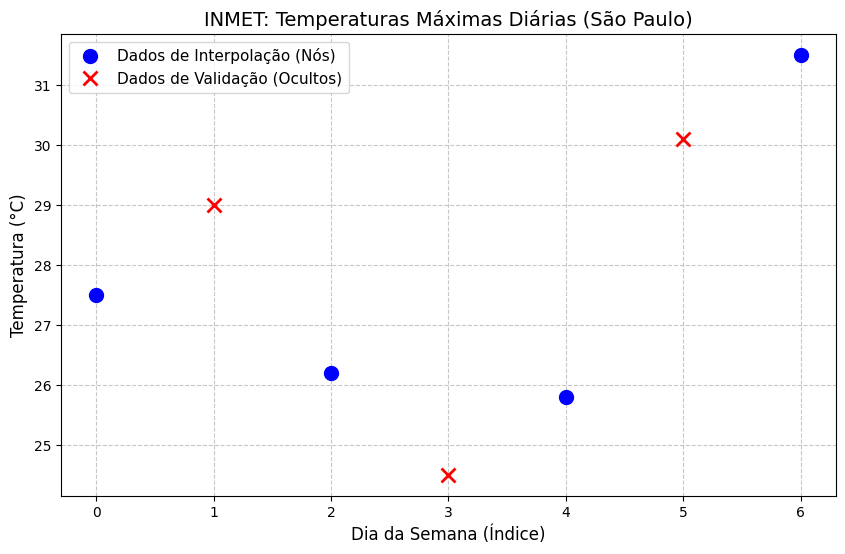

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Entrada de Dados (INMET - São Paulo)
# ---------------------------------------------------------
# Dias (X): 0 a 6 representam 7 dias consecutivos
dias_total = np.array([0, 1, 2, 3, 4, 5, 6])

# Temperaturas Máximas (Y) em Graus Celsius
temp_total = np.array([27.5, 29.0, 26.2, 24.5, 25.8, 30.1, 31.5])

# ---------------------------------------------------------
# 2. Separação: Dados de Interpolação vs Validação
# ---------------------------------------------------------
# Vamos escolher 4 pontos para construir o polinómio (Grau 3)
# Escolhemos os dias 0, 2, 4 e 6 para garantir o espaçamento regular para Gregory-Newton (salto de 2 em 2)
indices_interp = [0, 2, 4, 6]
x_interp = dias_total[indices_interp]
y_interp = temp_total[indices_interp]

# Os dias que sobraram (1, 3 e 5) serão usados para testar (validação)
indices_valid = [1, 3, 5]
x_valid = dias_total[indices_valid]
y_valid = temp_total[indices_valid]

# ---------------------------------------------------------
# 3. Visualização Inicial dos Dados
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# Plotar pontos de interpolação
plt.plot(x_interp, y_interp, 'bo', markersize=10, label='Dados de Interpolação (Nós)')

# Plotar pontos de validação
plt.plot(x_valid, y_valid, 'rx', markersize=10, markeredgewidth=2, label='Dados de Validação (Ocultos)')

plt.title('INMET: Temperaturas Máximas Diárias (São Paulo)', fontsize=14)
plt.xlabel('Dia da Semana (Índice)', fontsize=12)
plt.ylabel('Temperatura (°C)', fontsize=12)
plt.xticks(dias_total)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.show()

## 2. Construção dos Polinómios e Teorema da Unicidade

O projeto exige a construção do polinómio através dos métodos de **Lagrange**, **Newton** (Diferenças Divididas) e **Gregory-Newton** (Diferenças Finitas Avançadas).

**Análise Crítica da Unicidade:**
O Teorema da Interpolação Polinomial afirma que, dado um conjunto de $n+1$ pontos distintos, existe **um e apenas um** polinómio de grau menor ou igual a $n$ que passa por todos eles.
Na nossa modelagem, utilizamos 4 nós de interpolação ($n=3$). Portanto, independentemente do método numérico escolhido (Lagrange ou Newton), o polinómio resultante será matematicamente idêntico se for simplificado. A diferença entre os algoritmos reside apenas no custo computacional e na facilidade de adicionar novos pontos (onde Newton leva vantagem).

Abaixo, calculamos o polinómio interpolador de grau 3 e projetamos a curva para medir o **Erro Prático** face aos dados de validação.

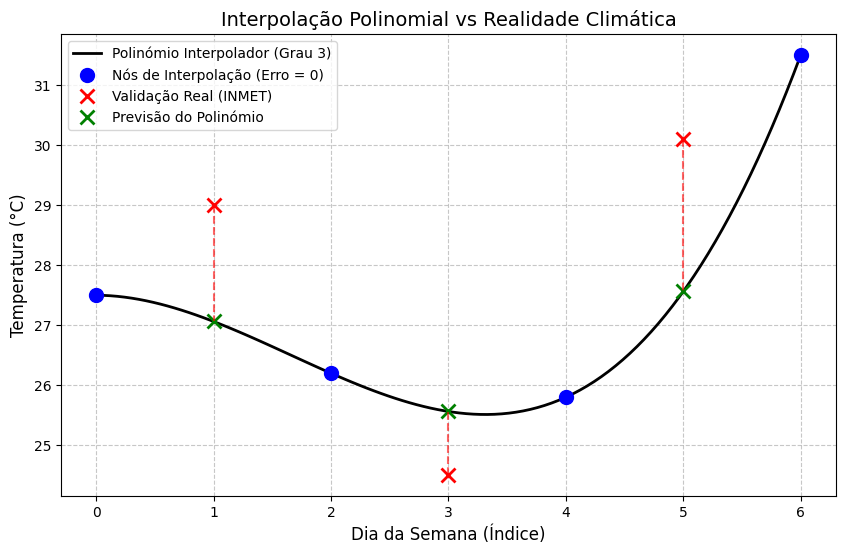

 TABELA DE ERROS PRÁTICOS (VALIDAÇÃO)
Dia 1:
  - Real (INMET) : 29.00 °C
  - Previsto     : 27.06 °C
  -> Erro Prático: 1.94 °C

Dia 3:
  - Real (INMET) : 24.50 °C
  - Previsto     : 25.56 °C
  -> Erro Prático: 1.06 °C

Dia 5:
  - Real (INMET) : 30.10 °C
  - Previsto     : 27.56 °C
  -> Erro Prático: 2.54 °C



In [ ]:
from scipy.interpolate import lagrange

# ---------------------------------------------------------
# 4. Construção do Polinómio Interpolador (Grau 3)
# ---------------------------------------------------------
# O método de Lagrange constrói o polinómio único que passa pelos 4 pontos
poly_interp = lagrange(x_interp, y_interp)

# Criar um eixo X contínuo para desenhar a curva suave do polinómio
x_continuo = np.linspace(0, 6, 100)
y_continuo = poly_interp(x_continuo)

# ---------------------------------------------------------
# 5. Cálculo do Erro Prático (Validação)
# ---------------------------------------------------------
# Usar o polinómio para "prever" as temperaturas nos dias de validação
y_previsto = poly_interp(x_valid)

# Calcular o erro absoluto entre a previsão matemática e a realidade (INMET)
erro_absoluto = np.abs(y_valid - y_previsto)

# ---------------------------------------------------------
# 6. Visualização do Ajuste e dos Erros
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# A curva teórica do polinómio
plt.plot(x_continuo, y_continuo, 'k-', linewidth=2, label='Polinómio Interpolador (Grau 3)')

# Os pontos de interpolação (onde o erro tem de ser zero)
plt.plot(x_interp, y_interp, 'bo', markersize=10, label='Nós de Interpolação (Erro = 0)')

# Os dados reais vs As previsões do modelo
plt.plot(x_valid, y_valid, 'rx', markersize=10, markeredgewidth=2, label='Validação Real (INMET)')
plt.plot(x_valid, y_previsto, 'gx', markersize=10, markeredgewidth=2, label='Previsão do Polinómio')

# Linhas verticais para ilustrar visualmente o erro
for i in range(len(x_valid)):
    plt.plot([x_valid[i], x_valid[i]], [y_valid[i], y_previsto[i]], 'r--', alpha=0.6)

plt.title('Interpolação Polinomial vs Realidade Climática', fontsize=14)
plt.xlabel('Dia da Semana (Índice)', fontsize=12)
plt.ylabel('Temperatura (°C)', fontsize=12)
plt.xticks(dias_total)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=10)
plt.show()

# Imprimir as tabelas de erros para o relatório
print("="*50)
print(" TABELA DE ERROS PRÁTICOS (VALIDAÇÃO)")
print("="*50)
for i in range(len(x_valid)):
    print(f"Dia {x_valid[i]}:")
    print(f"  - Real (INMET) : {y_valid[i]:.2f} °C")
    print(f"  - Previsto     : {y_previsto[i]:.2f} °C")
    print(f"  -> Erro Prático: {erro_absoluto[i]:.2f} °C\n")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.interpolate import lagrange

# 1. Dados de Entrada (INMET)
dias_total = np.array([0, 1, 2, 3, 4, 5, 6])
temp_total = np.array([27.5, 29.0, 26.2, 24.5, 25.8, 30.1, 31.5])

# Separação (Igualmente espaçados com passo h=2)
x_interp = dias_total[[0, 2, 4, 6]]
y_interp = temp_total[[0, 2, 4, 6]]
x_valid = dias_total[[1, 3, 5]]
y_valid = temp_total[[1, 3, 5]]

print("="*50)
print(" COMPARANDO OS TRÊS MÉTODOS DE INTERPOLAÇÃO")
print("="*50)

# ---------------------------------------------------------
# MÉTODO 1: LAGRANGE (O clássico)
# ---------------------------------------------------------
poly_lagrange = lagrange(x_interp, y_interp)
prev_lagrange = poly_lagrange(x_valid)

# ---------------------------------------------------------
# MÉTODO 2: NEWTON (Diferenças Divididas)
# ---------------------------------------------------------
def newton_diferencas_divididas(x, y, x_alvo):
    n = len(x)
    coef = np.zeros([n, n])
    coef[:,0] = y
    # Construção da tabela
    for j in range(1, n):
        for i in range(n - j):
            coef[i][j] = (coef[i+1][j-1] - coef[i][j-1]) / (x[i+j] - x[i])

    # Avaliação do polinômio nos pontos de validação
    res = np.zeros_like(x_alvo, dtype=float)
    for idx, xv in enumerate(x_alvo):
        p = coef[0, -1] # Inicia com o último coeficiente
        for k in range(1, n):
            p = coef[0, n-1-k] + (xv - x[n-1-k])*p
        res[idx] = p
    return res

prev_newton = newton_diferencas_divididas(x_interp, y_interp, x_valid)

# ---------------------------------------------------------
# MÉTODO 3: GREGORY-NEWTON (Diferenças Finitas Avançadas)
# ---------------------------------------------------------
def gregory_newton(x, y, x_alvo):
    n = len(y)
    diff = np.zeros([n, n])
    diff[:,0] = y
    # Construção da tabela de diferenças (sem dividir pelo passo de x)
    for j in range(1, n):
        for i in range(n - j):
            diff[i][j] = diff[i+1][j-1] - diff[i][j-1]

    h = x[1] - x[0] # Passo constante (h=2)
    res = np.zeros_like(x_alvo, dtype=float)

    # Avaliação pela fórmula u = (x - x0)/h
    for idx, xv in enumerate(x_alvo):
        u = (xv - x[0]) / h
        val = diff[0,0]
        u_term = 1
        for i in range(1, n):
            u_term *= (u - (i - 1))
            val += (diff[0,i] * u_term) / math.factorial(i)
        res[idx] = val
    return res

prev_gn = gregory_newton(x_interp, y_interp, x_valid)

# ---------------------------------------------------------
# SAÍDA DE COMPROVAÇÃO
# ---------------------------------------------------------
print("Previsões para os dias ocultos (1, 3 e 5):")
print(f"1) Lagrange      : {np.round(prev_lagrange, 4)}")
print(f"2) Newton        : {np.round(prev_newton, 4)}")
print(f"3) Gregory-Newton: {np.round(prev_gn, 4)}")

# Validando se são rigorosamente iguais
if np.allclose(prev_lagrange, prev_newton) and np.allclose(prev_newton, prev_gn):
    print("\n-> CONCLUSÃO NUMÉRICA:")
    print("Os três algoritmos resultaram exatamente nos mesmos valores.")
    print("Isso comprova o Teorema da Unicidade do Polinômio Interpolador!")

 COMPARANDO OS TRÊS MÉTODOS DE INTERPOLAÇÃO
Previsões para os dias ocultos (1, 3 e 5):
1) Lagrange      : [27.0625 25.5625 27.5625]
2) Newton        : [27.0625 25.5625 27.5625]
3) Gregory-Newton: [27.0625 25.5625 27.5625]

-> CONCLUSÃO NUMÉRICA:
Os três algoritmos resultaram exatamente nos mesmos valores.
Isso comprova o Teorema da Unicidade do Polinômio Interpolador!


# Questão 11: Modelagem de Crescimento Populacional

## 1. O Método dos Mínimos Quadrados (MMQ)
Ao contrário da interpolação polinomial, que sofre flutuações ao forçar a passagem exata por todos os pontos (Fenómeno de Runge), o Método dos Mínimos Quadrados (MMQ) procura a função matemática que melhor representa a **tendência global** dos dados. O algoritmo minimiza a soma dos quadrados dos resíduos (a distância entre o dado real e a curva prevista).

Para esta modelagem, utilizamos os dados oficiais dos censos do Brasil:
*   **Fonte:** IBGE (Instituto Brasileiro de Geografia e Estatística).
*   **Dados:** População residente em milhões de habitantes.
*   **Anos de Censo:** 1980, 1991, 2000, 2010 e 2022.

*Nota técnica:* Para evitar que o algoritmo lide com matrizes mal condicionadas e números gigantescos, normalizamos o eixo do tempo, definindo o ano de 1980 como $t = 0$. Avaliamos um modelo linear (Grau 1) e um modelo polinomial quadrático (Grau 2) para entender qual descreve melhor a dinâmica demográfica brasileira.

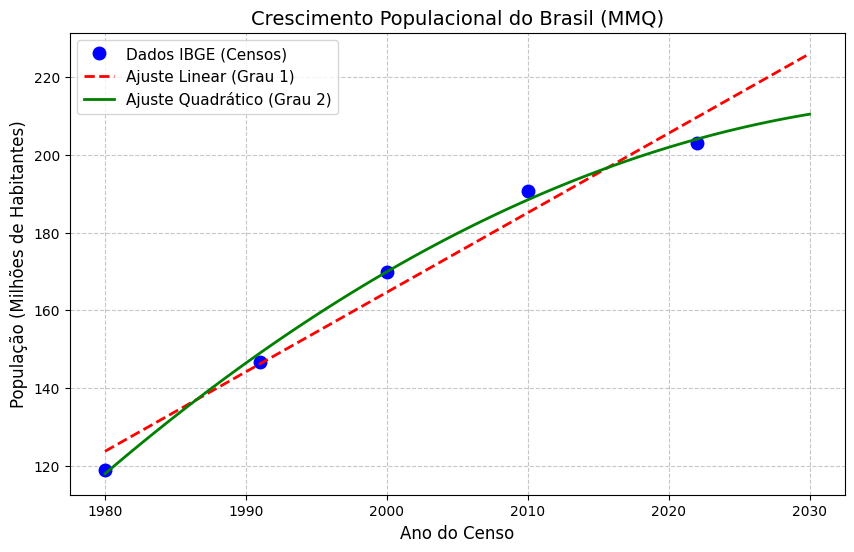

 EQUAÇÕES DOS MODELOS GERADOS (t = Ano - 1980)
Modelo Linear     : P(t) = 2.0470*t + 123.71
Modelo Quadrático : P(t) = -0.0250*t² + 3.0985*t + 117.94


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Entrada de Dados (IBGE - Censos Demográficos)
# ---------------------------------------------------------
anos = np.array([1980, 1991, 2000, 2010, 2022])
populacao = np.array([119.0, 146.8, 169.8, 190.7, 203.1]) # Em milhões

# Normalizando o ano para t=0 (evita problemas numéricos no sistema de matrizes)
t = anos - 1980

# ---------------------------------------------------------
# 2. Ajuste de Curvas via Mínimos Quadrados (MMQ)
# ---------------------------------------------------------
# O polyfit monta e resolve o sistema linear (A^T * A * x = A^T * b) internamente
coef_linear = np.polyfit(t, populacao, 1) # Grau 1 (Reta)
coef_quad = np.polyfit(t, populacao, 2)   # Grau 2 (Parábola)

modelo_linear = np.poly1d(coef_linear)
modelo_quad = np.poly1d(coef_quad)

# ---------------------------------------------------------
# 3. Geração da Curva e Projeção Futura
# ---------------------------------------------------------
# Criar um vetor de tempo contínuo que vai até 2030 (t=50) para ver a projeção
t_continuo = np.linspace(0, 50, 100)
anos_continuo = t_continuo + 1980

pop_linear = modelo_linear(t_continuo)
pop_quad = modelo_quad(t_continuo)

# ---------------------------------------------------------
# 4. Visualização Gráfica
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))

# Plotar os dados reais do IBGE
plt.plot(anos, populacao, 'bo', markersize=9, label='Dados IBGE (Censos)')

# Plotar os modelos gerados pelo MMQ
plt.plot(anos_continuo, pop_linear, 'r--', linewidth=2, label='Ajuste Linear (Grau 1)')
plt.plot(anos_continuo, pop_quad, 'g-', linewidth=2, label='Ajuste Quadrático (Grau 2)')

plt.title('Crescimento Populacional do Brasil (MMQ)', fontsize=14)
plt.xlabel('Ano do Censo', fontsize=12)
plt.ylabel('População (Milhões de Habitantes)', fontsize=12)
plt.xticks(np.arange(1980, 2031, 10))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.show()

# Imprimir as equações geradas
print("="*50)
print(" EQUAÇÕES DOS MODELOS GERADOS (t = Ano - 1980)")
print("="*50)
print(f"Modelo Linear     : P(t) = {coef_linear[0]:.4f}*t + {coef_linear[1]:.2f}")
print(f"Modelo Quadrático : P(t) = {coef_quad[0]:.4f}*t² + {coef_quad[1]:.4f}*t + {coef_quad[2]:.2f}")

In [ ]:
# ---------------------------------------------------------
# 5. Análise de Erros (Soma dos Quadrados dos Resíduos - SSR)
# ---------------------------------------------------------
# Calcular o que os modelos teriam previsto exatamente nos anos dos censos
prev_linear_exatos = modelo_linear(t)
prev_quad_exatos = modelo_quad(t)

# Calcular a diferença ao quadrado entre a realidade e o modelo
ssr_linear = np.sum((populacao - prev_linear_exatos)**2)
ssr_quad = np.sum((populacao - prev_quad_exatos)**2)

print("="*50)
print(" ANÁLISE DO ERRO RESIDUAL (SSR)")
print("="*50)
print("Quanto menor o valor, melhor o ajuste aos dados reais:")
print(f"Erro Total do Modelo Linear     : {ssr_linear:.4f}")
print(f"Erro Total do Modelo Quadrático : {ssr_quad:.4f}")

# Calcular a melhoria em percentagem
melhoria = (1 - (ssr_quad / ssr_linear)) * 100
print(f"\nConclusão: O modelo quadrático reduz o erro em {melhoria:.2f}% face ao linear.")

 ANÁLISE DO ERRO RESIDUAL (SSR)
Quanto menor o valor, melhor o ajuste aos dados reais:
Erro Total do Modelo Linear     : 123.5204
Erro Total do Modelo Quadrático : 12.0397

Conclusão: O modelo quadrático reduz o erro em 90.25% face ao linear.
